# Лабораторная работа №1. Метод k ближайших соседей (KNN)

План:
1. Выбор начальных условий: датасеты, практическая задача, метрики.
2. Бейзлайн на sklearn и его качество.
3. Улучшение бейзлайна: гипотезы, проверка на кросс-валидации, улучшенная модель.
4. Собственная реализация KNN: сравнение с бейзлайном, затем с улучшениями.
5. Выводы.

## 0. Подготовка окружения

Общий код вынесен в пакет `mllabs`: загрузка данных и признаки (`data.py`), метрики (`evaluation.py`), препроцессинг (`pipelines.py`) и собственные реализации алгоритмов (`models/`).

In [1]:
# Подключаем пакет mllabs из корня репозитория и импортируем библиотеки
import os, sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
os.environ["PYTHONPATH"] = str(ROOT)  # параллельные процессы joblib тоже должны видеть mllabs
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import make_pipeline

from mllabs import data as D
from mllabs.evaluation import (ResultStore, Timer, classification_metrics, compare_cv,
                               oof_threshold, regression_metrics)
from mllabs.models.knn import KNNClassifierScratch, KNNRegressorScratch
from mllabs.pipelines import bank_preprocessor, metro_preprocessor

pd.set_option("display.precision", 4)
sns.set_theme(style="whitegrid")
store = ResultStore("lab1_knn", "KNN")

## 1. Выбор начальных условий

### 1.1. Классификация: Bank Marketing (UCI 222)

Данные телемаркетинговых кампаний португальского банка: 45 211 звонков клиентам, 16 признаков (возраст, профессия, баланс, наличие кредитов, история прошлых кампаний и т.д.). Целевая переменная `y` — открыл ли клиент срочный депозит.

**Практическая задача.** Обзвон стоит денег и раздражает клиентов. Модель, которая заранее ранжирует клиентов по вероятности согласия, позволяет звонить сначала тем, кто с большей вероятностью откроет депозит, и сократить число пустых звонков.

**Важно:** признак `duration` (длительность звонка) убран. Он становится известен только после звонка и почти однозначно определяет ответ, то есть это утечка целевой переменной, а модель с ним бесполезна на практике.

### 1.2. Регрессия: Metro Interstate Traffic Volume (UCI 492)

Почасовой трафик на шоссе I-94 (Миннеаполис — Сент-Пол) с 2012 по 2018 год вместе с погодой и праздниками. Целевая переменная — `traffic_volume`, число машин в час.

**Практическая задача.** Прогноз загрузки дороги нужен для планирования ремонтных работ, управления светофорами и предупреждения водителей о пробках.

In [2]:
# Загружаем оба датасета целиком, чтобы посмотреть на структуру
bank = D.load_bank()
metro = D.load_metro()
print("Bank:", bank.shape, "| Metro после удаления дублей по времени:", metro.shape)
display(bank.head(3))
display(metro.head(3))

Bank: (45211, 16) | Metro после удаления дублей по времени: (40575, 9)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,1,-1,0,unknown,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,1,-1,0,unknown,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,1,-1,0,unknown,0


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767


### 1.3. Разведочный анализ

Смотрим на баланс классов, на зависимость отклика от истории прошлых кампаний и на то, как трафик зависит от часа и дня недели.

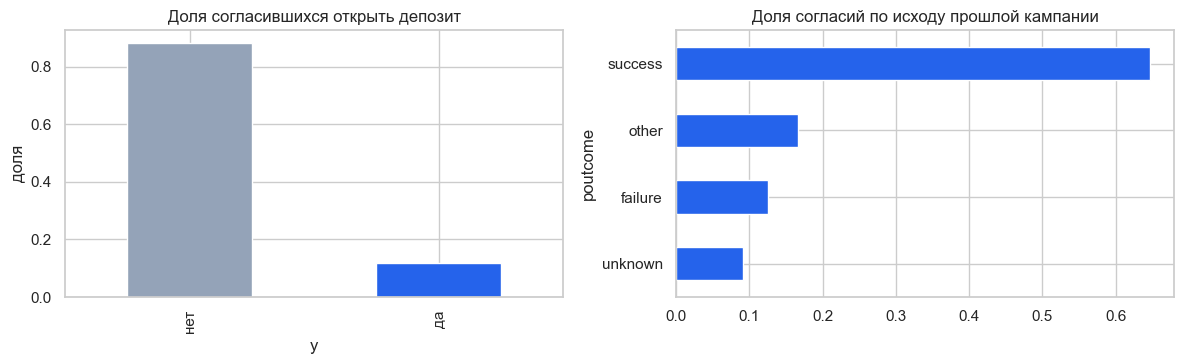

Доля положительного класса: 0.117


In [3]:
# Баланс классов и доля успеха в зависимости от исхода прошлой кампании
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
bank["y"].value_counts(normalize=True).rename({0: "нет", 1: "да"}).plot.bar(ax=axes[0], color=["#94a3b8", "#2563eb"])
axes[0].set_title("Доля согласившихся открыть депозит")
axes[0].set_ylabel("доля")
bank.groupby("poutcome")["y"].mean().sort_values().plot.barh(ax=axes[1], color="#2563eb")
axes[1].set_title("Доля согласий по исходу прошлой кампании")
plt.tight_layout()
plt.show()
print("Доля положительного класса:", round(bank["y"].mean(), 4))

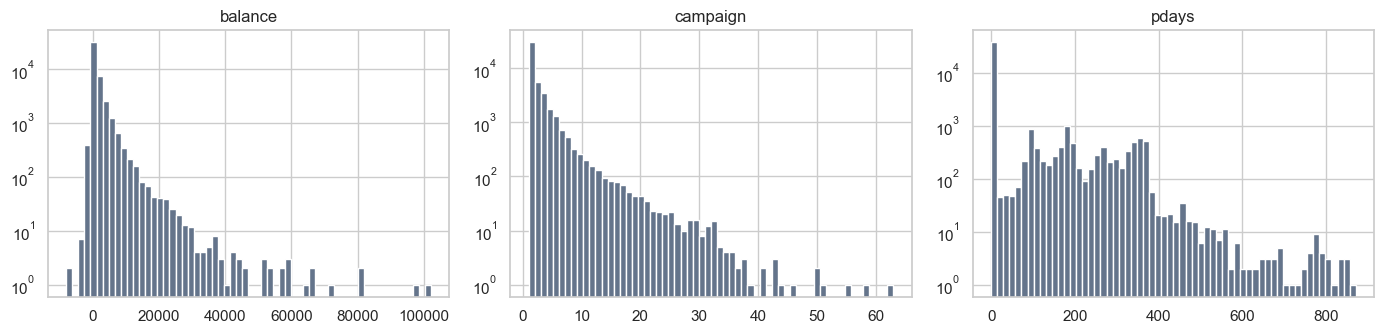

Клиентов, которым раньше не звонили (pdays = -1): 0.817


In [4]:
# Распределения скошенных числовых признаков: баланс, число звонков, pdays
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, ["balance", "campaign", "pdays"]):
    ax.hist(bank[col], bins=60, color="#64748b")
    ax.set_title(col)
    ax.set_yscale("log")
plt.tight_layout()
plt.show()
print("Клиентов, которым раньше не звонили (pdays = -1):", round((bank["pdays"] == -1).mean(), 3))

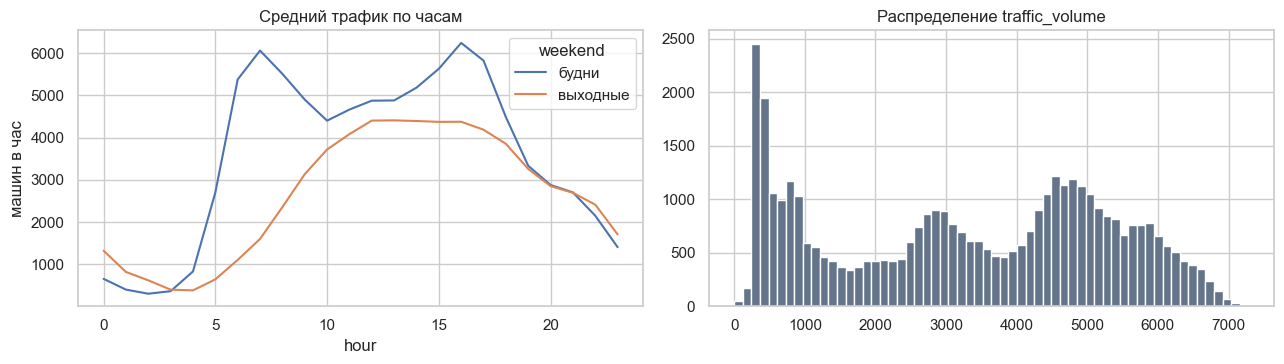

In [5]:
# Средний трафик по часам для будней и выходных, распределение целевой переменной
m = metro.assign(hour=metro.date_time.dt.hour,
                 weekend=np.where(metro.date_time.dt.dayofweek >= 5, "выходные", "будни"))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
m.groupby(["hour", "weekend"])["traffic_volume"].mean().unstack().plot(ax=axes[0])
axes[0].set_title("Средний трафик по часам")
axes[0].set_ylabel("машин в час")
axes[1].hist(metro["traffic_volume"], bins=60, color="#64748b")
axes[1].set_title("Распределение traffic_volume")
plt.tight_layout()
plt.show()

In [6]:
# Аномалии в погодных данных: нулевая температура в Кельвинах и гигантский дождь
print("temp == 0 K:", int((metro["temp"] == 0).sum()), "строк")
print("rain_1h > 60 мм:", int((metro["rain_1h"] > 60).sum()), "строк, максимум", metro["rain_1h"].max())
print("Праздник отмечен только в полночь:", metro.loc[metro.holiday.notna(), "date_time"].dt.hour.unique())

temp == 0 K: 10 строк
rain_1h > 60 мм: 1 строк, максимум 9831.3
Праздник отмечен только в полночь: [0]


**Наблюдения.**
- Классы несбалансированы: согласились около 11,7% клиентов. Accuracy тут вводит в заблуждение: модель «всем ответят нет» даёт 88%.
- Сильнейший сигнал — успех прошлой кампании (`poutcome = success`). `pdays = -1` — не число, а маркер «раньше не звонили» (так у 82% клиентов). `balance` и `campaign` сильно скошены.
- Трафик почти полностью определяется временем: в будни два пика (утро и вечер), в выходные — один пологий дневной горб. Погода вторична.
- В данных есть ошибки: температура 0 K и дождь 9831 мм за час, а праздник отмечен только в 00:00 своего дня.

### 1.4. Разбиение и метрики

**Bank:** стратифицированное разбиение 80/20, кросс-валидация — `StratifiedKFold(5)`.

**Metro:** разбиение **по времени** — последние 20% наблюдений (с конца октября 2017 года) идут в тест, кросс-валидация — `TimeSeriesSplit(5)`. Случайное разбиение дало бы утечку: соседние часы почти одинаковы, и модель видела бы «будущее».

**Метрики классификации:**
- **ROC-AUC** — основная: качество ранжирования клиентов, не зависит от порога и от дисбаланса так сильно, как accuracy. Именно ранжирование нужно для очереди обзвона.
- **PR-AUC** — средняя точность; чувствительнее к качеству в редком положительном классе.
- **F1** (а также precision и recall) — качество итогового решения «звонить / не звонить» при выбранном пороге. Для улучшенных моделей порог подбирается по out-of-fold прогнозам на train, тест для этого не используется.

**Метрики регрессии:**
- **MAE** — средняя ошибка в машинах в час, легко интерпретируется.
- **RMSE** — сильнее штрафует большие промахи (например, пропущенный пик), что важно для планирования.
- **R²** — доля объяснённой дисперсии, удобна для сравнения моделей между собой.

In [7]:
# Делим данные: стратифицированно для банка и хронологически для трафика
Xb_train, Xb_test, yb_train, yb_test = D.bank_split()
Xm_train, Xm_test, ym_train, ym_test = D.metro_split()
bank_cv, metro_cv = D.bank_cv(), D.metro_cv()
print("Bank train/test:", Xb_train.shape, Xb_test.shape, "| доля 1 в тесте:", round(yb_test.mean(), 4))
print("Metro train:", Xm_train.date_time.min(), "—", Xm_train.date_time.max())
print("Metro test: ", Xm_test.date_time.min(), "—", Xm_test.date_time.max())

Bank train/test: (36168, 15) (9043, 15) | доля 1 в тесте: 0.117
Metro train: 2012-10-02 09:00:00 — 2017-10-26 17:00:00
Metro test:  2017-10-26 18:00:00 — 2018-09-30 23:00:00


## 2. Бейзлайн

Бейзлайн для всех пяти лабораторных одинаковый, чтобы их можно было сравнивать:
- **Bank:** числовые признаки как есть, категориальные — one-hot.
- **Metro:** погода как есть, из даты — час, день недели и месяц числами, флаг праздника, one-hot погодной метки.

Модель — `KNeighborsClassifier` / `KNeighborsRegressor` с параметрами по умолчанию (k = 5). Порог классификации — 0.5.

In [8]:
# Обучаем бейзлайн KNN для классификации и оцениваем на тесте
knn_clf_base = make_pipeline(bank_preprocessor(), KNeighborsClassifier(n_jobs=-1))
with Timer() as t:
    knn_clf_base.fit(Xb_train, yb_train)
proba = knn_clf_base.predict_proba(Xb_test)[:, 1]
store.add("classification", "baseline", "KNeighborsClassifier(k=5)",
          classification_metrics(yb_test, proba), t.seconds)

# То же для регрессии
knn_reg_base = make_pipeline(metro_preprocessor(rich=False), KNeighborsRegressor(n_jobs=-1))
with Timer() as t:
    knn_reg_base.fit(Xm_train, ym_train)
store.add("regression", "baseline", "KNeighborsRegressor(k=5)",
          regression_metrics(ym_test, knn_reg_base.predict(Xm_test)), t.seconds)

display(store.table("classification"))
display(store.table("regression"))

,model,ROC-AUC,PR-AUC,F1,Precision,Recall,threshold,fit_seconds
Этап,,,,,,,,
Бейзлайн sklearn,KNeighborsClassifier(k=5),0.6116,0.1934,0.1814,0.4251,0.1153,0.5,0.0739


,model,MAE,RMSE,R2,fit_seconds
Этап,,,,,
Бейзлайн sklearn,KNeighborsRegressor(k=5),452.8359,696.4392,0.875,0.0205


**Выводы по бейзлайну.**
- Классификация: ROC-AUC = 0.612 — немногим лучше случайного угадывания (0.5). При пороге 0.5 модель находит только 11.5% согласившихся (recall), F1 = 0.18. Причины видны заранее: признаки не масштабированы, и расстояние почти целиком определяет `balance` (тысячи евро), а 5 соседей дают очень грубые вероятности (0, 0.2, 0.4, …).
- Регрессия: R² = 0.875, MAE ≈ 453 машины в час. Неплохо, потому что час и день недели — сильные признаки даже в виде чисел, но масштабы признаков тоже не согласованы.

## 3. Улучшение бейзлайна

### 3.1. Гипотезы

**Классификация:**
1. KNN считает расстояния, поэтому признаки в разных масштабах (баланс в тысячах евро против бинарных one-hot) искажают соседство. **Масштабирование** должно сильно помочь.
2. **Новые признаки**: логарифмы скошенных `balance`, `campaign`, `previous`, флаг «раньше звонили» вместо `pdays = -1`.
3. **Подбор k и весов соседей**: при редком классе и шумных данных 5 соседей — слишком мало, вероятности получаются грубыми (кратны 0.2).
4. **Подбор порога** по F1 вместо 0.5.

**Регрессия:**
1. **Масштабирование** — по той же причине.
2. **Циклическое кодирование** времени (sin/cos часа, дня недели и месяца) и **тип дня** (будни / суббота / воскресенье / праздник; праздник распространён на весь день).
3. **Убрать погоду**: для KNN лишние слабые признаки — шум в расстоянии.
4. **Подбор k и весов** на `TimeSeriesSplit`.

Каждая гипотеза проверяется на кросс-валидации только по обучающей выборке.

In [9]:
# Проверяем гипотезы для классификации на 5-fold стратифицированной CV
clf_scoring = {"ROC-AUC": "roc_auc", "PR-AUC": "average_precision"}
clf_hyp = compare_cv({
    "0. Бейзлайн": make_pipeline(bank_preprocessor(), KNeighborsClassifier()),
    "1. + масштабирование": make_pipeline(bank_preprocessor(scale=True), KNeighborsClassifier()),
    "2. + новые признаки": make_pipeline(bank_preprocessor(rich=True, scale=True), KNeighborsClassifier()),
    "3. + k = 51": make_pipeline(bank_preprocessor(rich=True, scale=True), KNeighborsClassifier(51)),
}, Xb_train, yb_train, bank_cv, clf_scoring)
clf_hyp

,ROC-AUC,ROC-AUC std,PR-AUC,PR-AUC std
Гипотеза,,,,
0. Бейзлайн,0.6108,0.0058,0.1824,0.0048
1. + масштабирование,0.6910,0.0084,0.2817,0.0110
2. + новые признаки,0.6944,0.0060,0.2843,0.0111
3. + k = 51,0.7609,0.0054,0.3860,0.0129


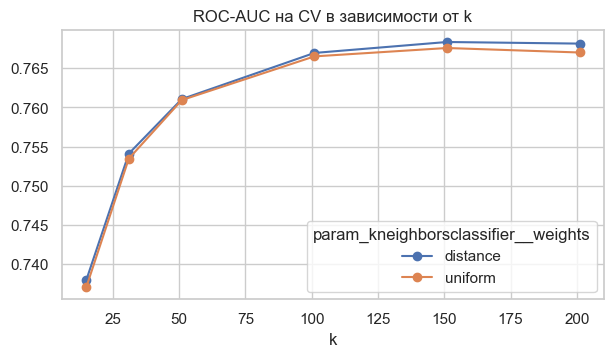

Лучшие параметры: {'kneighborsclassifier__n_neighbors': 151, 'kneighborsclassifier__weights': 'distance'} | ROC-AUC CV: 0.7684


In [10]:
# Подбираем k и схему весов на кросс-валидации (метрика — ROC-AUC)
clf_search = GridSearchCV(
    make_pipeline(bank_preprocessor(rich=True, scale=True), KNeighborsClassifier()),
    {"kneighborsclassifier__n_neighbors": [15, 31, 51, 101, 151, 201],
     "kneighborsclassifier__weights": ["uniform", "distance"]},
    scoring="roc_auc", cv=bank_cv, n_jobs=-1)
clf_search.fit(Xb_train, yb_train)
res = pd.DataFrame(clf_search.cv_results_)
res.pivot(index="param_kneighborsclassifier__n_neighbors",
          columns="param_kneighborsclassifier__weights", values="mean_test_score").plot(marker="o", figsize=(7, 3.5))
plt.title("ROC-AUC на CV в зависимости от k")
plt.xlabel("k")
plt.show()
print("Лучшие параметры:", clf_search.best_params_, "| ROC-AUC CV:", round(clf_search.best_score_, 4))

In [11]:
# Проверяем гипотезы для регрессии на TimeSeriesSplit
reg_scoring = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"}
TIME_FEATURES = D.METRO_CYCLIC
reg_hyp = compare_cv({
    "0. Бейзлайн": make_pipeline(metro_preprocessor(rich=False), KNeighborsRegressor()),
    "1. + масштабирование": make_pipeline(metro_preprocessor(rich=False, scale=True), KNeighborsRegressor()),
    "2. + цикл. время и тип дня": make_pipeline(
        metro_preprocessor(TIME_FEATURES + D.METRO_WEATHER, ["daytype", "weather_main"], scale=True),
        KNeighborsRegressor()),
    "3. только время и тип дня": make_pipeline(
        metro_preprocessor(TIME_FEATURES, ["daytype"], scale=True), KNeighborsRegressor()),
}, Xm_train, ym_train, metro_cv, reg_scoring)
reg_hyp

,MAE,MAE std,RMSE,RMSE std,R2,R2 std
Гипотеза,,,,,,
0. Бейзлайн,610.6308,161.0257,902.3438,224.9872,0.7804,0.1132
1. + масштабирование,617.3964,93.0661,896.3164,115.3990,0.7921,0.0511
2. + цикл. время и тип дня,469.4354,51.0474,688.5666,74.2342,0.8778,0.0235
3. только время и тип дня,312.8120,44.2891,488.4064,80.7862,0.9373,0.0185


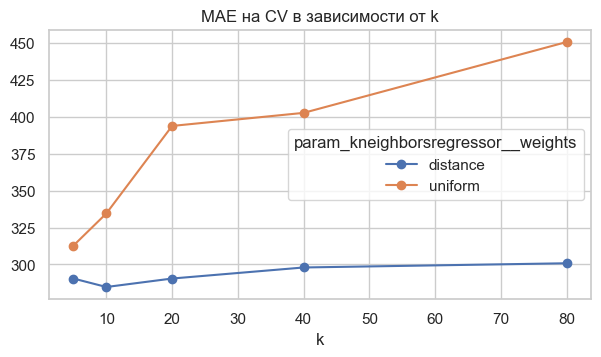

Лучшие параметры: {'kneighborsregressor__n_neighbors': 10, 'kneighborsregressor__weights': 'distance'} | MAE CV: 284.8


In [12]:
# Подбираем k и веса для лучшего набора признаков
reg_search = GridSearchCV(
    make_pipeline(metro_preprocessor(TIME_FEATURES, ["daytype"], scale=True), KNeighborsRegressor()),
    {"kneighborsregressor__n_neighbors": [5, 10, 20, 40, 80],
     "kneighborsregressor__weights": ["uniform", "distance"]},
    scoring="neg_mean_absolute_error", cv=metro_cv, n_jobs=-1)
reg_search.fit(Xm_train, ym_train)
res = pd.DataFrame(reg_search.cv_results_)
(-res.pivot(index="param_kneighborsregressor__n_neighbors",
            columns="param_kneighborsregressor__weights", values="mean_test_score")).plot(marker="o", figsize=(7, 3.5))
plt.title("MAE на CV в зависимости от k")
plt.xlabel("k")
plt.show()
print("Лучшие параметры:", reg_search.best_params_, "| MAE CV:", round(-reg_search.best_score_, 1))

**Результаты проверки гипотез.**

*Классификация:*
- Масштабирование — главный эффект: ROC-AUC на CV вырос с 0.611 до 0.691. Гипотеза подтверждена.
- Новые признаки дали небольшой, но стабильный прирост (0.691 → 0.694): после логарифмирования хвосты `balance` и `campaign` перестают доминировать в расстоянии. Подтверждена.
- Число соседей — второй по силе фактор: k = 51 даёт 0.761, а поиск по сетке выбрал **k = 151 с весами по расстоянию** (0.768 на CV). При редком классе нужно много соседей, чтобы оценка доли согласий была устойчивой. Подтверждена.

*Регрессия:*
- Масштабирование само по себе MAE не улучшило (611 → 617), но заметно снизило разброс между фолдами. В исходных признаках «правильный» вес уже был у часа (диапазон 0–23), поэтому выравнивание масштабов не помогло. Гипотеза **не подтвердилась**.
- Циклическое время и тип дня: MAE 611 → 469. Подтверждена: соседями стали часы с похожим положением в сутках и неделе.
- Удаление погоды дало ещё больший эффект: MAE 469 → 313. Для KNN слабые признаки — это шум в расстоянии, и они «размывают» соседство по времени. Подтверждена.
- Лучшие параметры: **k = 10, веса по расстоянию**.

### 3.2. Улучшенный бейзлайн

Собираем лучшие решения: для классификации — масштабирование, новые признаки, подобранные k и веса, порог по F1 из out-of-fold прогнозов. Для регрессии — циклическое время, тип дня, масштабирование, подобранные k и веса.

In [13]:
# Классификация: лучшая модель из поиска и порог по out-of-fold прогнозам train
knn_clf_best = clf_search.best_estimator_
thr = oof_threshold(knn_clf_best, Xb_train, yb_train, bank_cv)
with Timer() as t:
    knn_clf_best.fit(Xb_train, yb_train)
proba = knn_clf_best.predict_proba(Xb_test)[:, 1]
k, w = (clf_search.best_params_[f"kneighborsclassifier__{p}"] for p in ("n_neighbors", "weights"))
store.add("classification", "improved", f"KNN(k={k}, {w}) + scale + features",
          classification_metrics(yb_test, proba, thr), t.seconds)

# Регрессия: лучшая модель из поиска
knn_reg_best = reg_search.best_estimator_
with Timer() as t:
    knn_reg_best.fit(Xm_train, ym_train)
k, w = (reg_search.best_params_[f"kneighborsregressor__{p}"] for p in ("n_neighbors", "weights"))
store.add("regression", "improved", f"KNN(k={k}, {w}) + cyclic time + daytype",
          regression_metrics(ym_test, knn_reg_best.predict(Xm_test)), t.seconds)

display(store.table("classification"))
display(store.table("regression"))

,model,ROC-AUC,PR-AUC,F1,Precision,Recall,threshold,fit_seconds
Этап,,,,,,,,
Бейзлайн sklearn,KNeighborsClassifier(k=5),0.6116,0.1934,0.1814,0.4251,0.1153,0.50,0.0739
Улучшенный sklearn,"KNN(k=151, distance) + scale + features",0.7785,0.4073,0.4382,0.4024,0.4811,0.17,0.0922


,model,MAE,RMSE,R2,fit_seconds
Этап,,,,,
Бейзлайн sklearn,KNeighborsRegressor(k=5),452.8359,696.4392,0.8750,0.0205
Улучшенный sklearn,"KNN(k=10, distance) + cyclic time + daytype",245.5219,404.2683,0.9579,0.1225


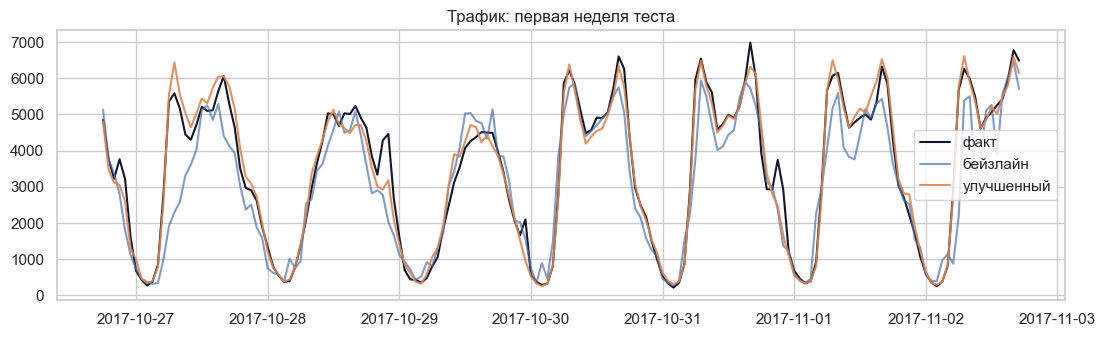

In [14]:
# Как улучшенная модель ловит суточный профиль: неделя из теста
week = slice(0, 24 * 7)
plt.figure(figsize=(13, 3.5))
plt.plot(Xm_test.date_time.iloc[week], ym_test.iloc[week], label="факт", color="#0f172a")
plt.plot(Xm_test.date_time.iloc[week], knn_reg_base.predict(Xm_test.iloc[week]), label="бейзлайн", alpha=.7)
plt.plot(Xm_test.date_time.iloc[week], knn_reg_best.predict(Xm_test.iloc[week]), label="улучшенный", alpha=.9)
plt.legend()
plt.title("Трафик: первая неделя теста")
plt.show()

**Улучшенный бейзлайн против бейзлайна (тест).**

| | ROC-AUC | PR-AUC | F1 | MAE | R² |
|---|---|---|---|---|---|
| Бейзлайн | 0.612 | 0.193 | 0.181 | 452.8 | 0.875 |
| Улучшенный | **0.779** | **0.407** | **0.438** | **245.5** | **0.958** |

- ROC-AUC вырос на 0.17, PR-AUC удвоился. Подбор порога (0.17 вместо 0.5) поднял recall с 12% до 48% при той же точности около 40%, поэтому F1 вырос в 2.4 раза.
- Ошибка прогноза трафика уменьшилась почти вдвое: 453 → 246 машин в час. На графике видно, что улучшенная модель точно повторяет утренний и вечерний пики будней.

## 4. Собственная реализация KNN

`mllabs/models/knn.py`: полный перебор на numpy. Квадраты расстояний считаются матрично как ‖a‖² + ‖b‖² − 2ab по блокам тестовых объектов, k ближайших находятся через `np.argpartition`. Классификатор возвращает долю соседей класса 1 (или взвешенную по 1/расстояние), регрессор — среднее значение соседей.

### 4.1. Те же условия, что у бейзлайна

In [15]:
# Своя реализация на признаках бейзлайна, k = 5, порог 0.5
own_clf = make_pipeline(bank_preprocessor(), KNNClassifierScratch(n_neighbors=5))
with Timer() as t:
    own_clf.fit(Xb_train, yb_train)
proba_own = own_clf.predict_proba(Xb_test)[:, 1]
store.add("classification", "scratch", "KNNClassifierScratch(k=5)",
          classification_metrics(yb_test, proba_own), t.seconds)

own_reg = make_pipeline(metro_preprocessor(rich=False), KNNRegressorScratch(n_neighbors=5))
with Timer() as t:
    own_reg.fit(Xm_train, ym_train)
store.add("regression", "scratch", "KNNRegressorScratch(k=5)",
          regression_metrics(ym_test, own_reg.predict(Xm_test)), t.seconds)

# Сверяем прогнозы со sklearn. Расхождения возможны только там, где несколько соседей
# стоят на одинаковом расстоянии (one-hot признаки дают много таких «ничьих»)
same = np.isclose(proba_own, knn_clf_base.predict_proba(Xb_test)[:, 1])
print(f"Совпадающих вероятностей со sklearn: {same.mean():.1%}")
display(store.table("classification").loc[["Бейзлайн sklearn", "Своя реализация"]])
display(store.table("regression").loc[["Бейзлайн sklearn", "Своя реализация"]])

Совпадающих вероятностей со sklearn: 99.1%


,model,ROC-AUC,PR-AUC,F1,Precision,Recall,threshold,fit_seconds
Этап,,,,,,,,
Бейзлайн sklearn,KNeighborsClassifier(k=5),0.6116,0.1934,0.1814,0.4251,0.1153,0.5,0.0739
Своя реализация,KNNClassifierScratch(k=5),0.6121,0.1938,0.1814,0.4251,0.1153,0.5,0.0736


,model,MAE,RMSE,R2,fit_seconds
Этап,,,,,
Бейзлайн sklearn,KNeighborsRegressor(k=5),452.8359,696.4392,0.8750,0.0205
Своя реализация,KNNRegressorScratch(k=5),452.8544,696.8683,0.8749,0.0193


**Своя реализация против бейзлайна sklearn.** Метрики совпадают с точностью до третьего знака (ROC-AUC 0.612 против 0.612, MAE 452.9 против 452.8). Небольшие отличия отдельных прогнозов возникают, когда несколько соседей стоят на одинаковом расстоянии: one-hot признаки дают много таких «ничьих», и реализации выбирают из них разных соседей. Алгоритм реализован верно.

### 4.2. Своя реализация с техниками улучшенного бейзлайна

Те же признаки, масштабирование, k и веса, что у лучшей модели sklearn. Порог классификации подбирается по out-of-fold прогнозам уже своей модели.

In [16]:
# Переносим улучшения в свою реализацию
k, w = (clf_search.best_params_[f"kneighborsclassifier__{p}"] for p in ("n_neighbors", "weights"))
own_clf_best = make_pipeline(bank_preprocessor(rich=True, scale=True), KNNClassifierScratch(k, w))
thr_own = oof_threshold(own_clf_best, Xb_train, yb_train, bank_cv)
with Timer() as t:
    own_clf_best.fit(Xb_train, yb_train)
store.add("classification", "scratch_improved", f"KNNClassifierScratch(k={k}, {w}) + scale + features",
          classification_metrics(yb_test, own_clf_best.predict_proba(Xb_test)[:, 1], thr_own), t.seconds)

k, w = (reg_search.best_params_[f"kneighborsregressor__{p}"] for p in ("n_neighbors", "weights"))
own_reg_best = make_pipeline(metro_preprocessor(TIME_FEATURES, ["daytype"], scale=True), KNNRegressorScratch(k, w))
with Timer() as t:
    own_reg_best.fit(Xm_train, ym_train)
store.add("regression", "scratch_improved", f"KNNRegressorScratch(k={k}, {w}) + cyclic time + daytype",
          regression_metrics(ym_test, own_reg_best.predict(Xm_test)), t.seconds)

display(store.table("classification"))
display(store.table("regression"))

,model,ROC-AUC,PR-AUC,F1,Precision,Recall,threshold,fit_seconds
Этап,,,,,,,,
Бейзлайн sklearn,KNeighborsClassifier(k=5),0.6116,0.1934,0.1814,0.4251,0.1153,0.50,0.0739
Улучшенный sklearn,"KNN(k=151, distance) + scale + features",0.7785,0.4073,0.4382,0.4024,0.4811,0.17,0.0922
Своя реализация,KNNClassifierScratch(k=5),0.6121,0.1938,0.1814,0.4251,0.1153,0.50,0.0736
Своя реализация + улучшения,"KNNClassifierScratch(k=151, distance) + scale ...",0.7784,0.4073,0.4382,0.4024,0.4811,0.17,0.0849


,model,MAE,RMSE,R2,fit_seconds
Этап,,,,,
Бейзлайн sklearn,KNeighborsRegressor(k=5),452.8359,696.4392,0.8750,0.0205
Улучшенный sklearn,"KNN(k=10, distance) + cyclic time + daytype",245.5219,404.2683,0.9579,0.1225
Своя реализация,KNNRegressorScratch(k=5),452.8544,696.8683,0.8749,0.0193
Своя реализация + улучшения,"KNNRegressorScratch(k=10, distance) + cyclic t...",242.0824,403.0895,0.9581,0.0630


**Своя реализация с улучшениями против улучшенного sklearn.** Качество совпадает: ROC-AUC 0.778 против 0.779 и тот же порог 0.17, MAE 242.1 против 245.5. Регрессия у своей реализации даже чуть лучше — это снова разный выбор среди соседей на равном расстоянии: признаки только из времени повторяются каждую неделю, поэтому у многих часов есть десятки точных копий. Все улучшения из пункта 3 перенеслись в свою реализацию без потерь.

In [17]:
# Сохраняем метрики для итогового сравнения всех алгоритмов
print("Сохранено:", store.save().name)

Сохранено: lab1_knn.json


## 5. Выводы

1. KNN очень чувствителен к представлению данных: одни и те же 5 соседей дают ROC-AUC 0.61 или 0.69 в зависимости от масштабирования, а для регрессии отказ от погодных признаков снизил ошибку на треть.
2. На данных с редким положительным классом нужно большое k (151): вероятности становятся гладкими, и ранжирование улучшается.
3. Лучший результат KNN: **ROC-AUC 0.779** в классификации и **MAE 245, R² 0.958** в регрессии.
4. Собственная реализация (полный перебор на numpy) воспроизводит sklearn и в базовой, и в улучшенной конфигурации.
5. Ограничение метода: прогноз требует перебора всей обучающей выборки, поэтому KNN медленно предсказывает и плохо масштабируется на большие данные.